# Kalshi Perps: Funding at Inception

pooled across all 13 crypto perp
markets Kalshi has launched (staggered over ~7 launch waves), funding rate
trajectories plotted against days since each market's own launch show a
consistent pattern — negative funding (shorts paid by longs; perp trading below
reference) clustered in the first ~10-15 days, decaying toward zero as each
market matures.

This is measurable here specifically because Kalshi is under two months old and
we have funding data from hour zero of multiple independent launches.

Loads only CSVs from kalshi_data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA = Path("kalshi_data")

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e5e5e5",
    "grid.linewidth": 0.6,
    "font.size": 10,
})

C_KALSHI = "#0072B2"  # Okabe-Ito blue

In [2]:
funding = pd.read_csv(DATA / "funding_rates_all.csv")
funding["funding_time"] = pd.to_datetime(funding["funding_time"], utc=True)

launch_date = funding.groupby("market_ticker")["funding_time"].min()
active_tickers = sorted(launch_date.index)
print(f"{len(active_tickers)} active tickers: {active_tickers}")

funding["days_since_launch"] = (
    funding["funding_time"] - funding["market_ticker"].map(launch_date)
).dt.total_seconds() / 86400

def short_name(ticker):
    return ticker.replace("KX", "").replace("PERP", "")

13 active tickers: ['KXBCHPERP', 'KXBTCPERP', 'KXDOGEPERP', 'KXETHPERP', 'KXHYPEPERP', 'KXKSHIBPERP', 'KXLINKPERP', 'KXLTCPERP', 'KXNEARPERP', 'KXSOLPERP', 'KXSUIPERP', 'KXXRPPERP', 'KXZECPERP']


## Funding rate since inception, per market

funding_rate is Kalshi's own estimate of the mark-vs-reference premium:
negative means the perp traded *below* reference and shorts collected from
longs. Each panel is its own inception event, all on the same days-since-launch.

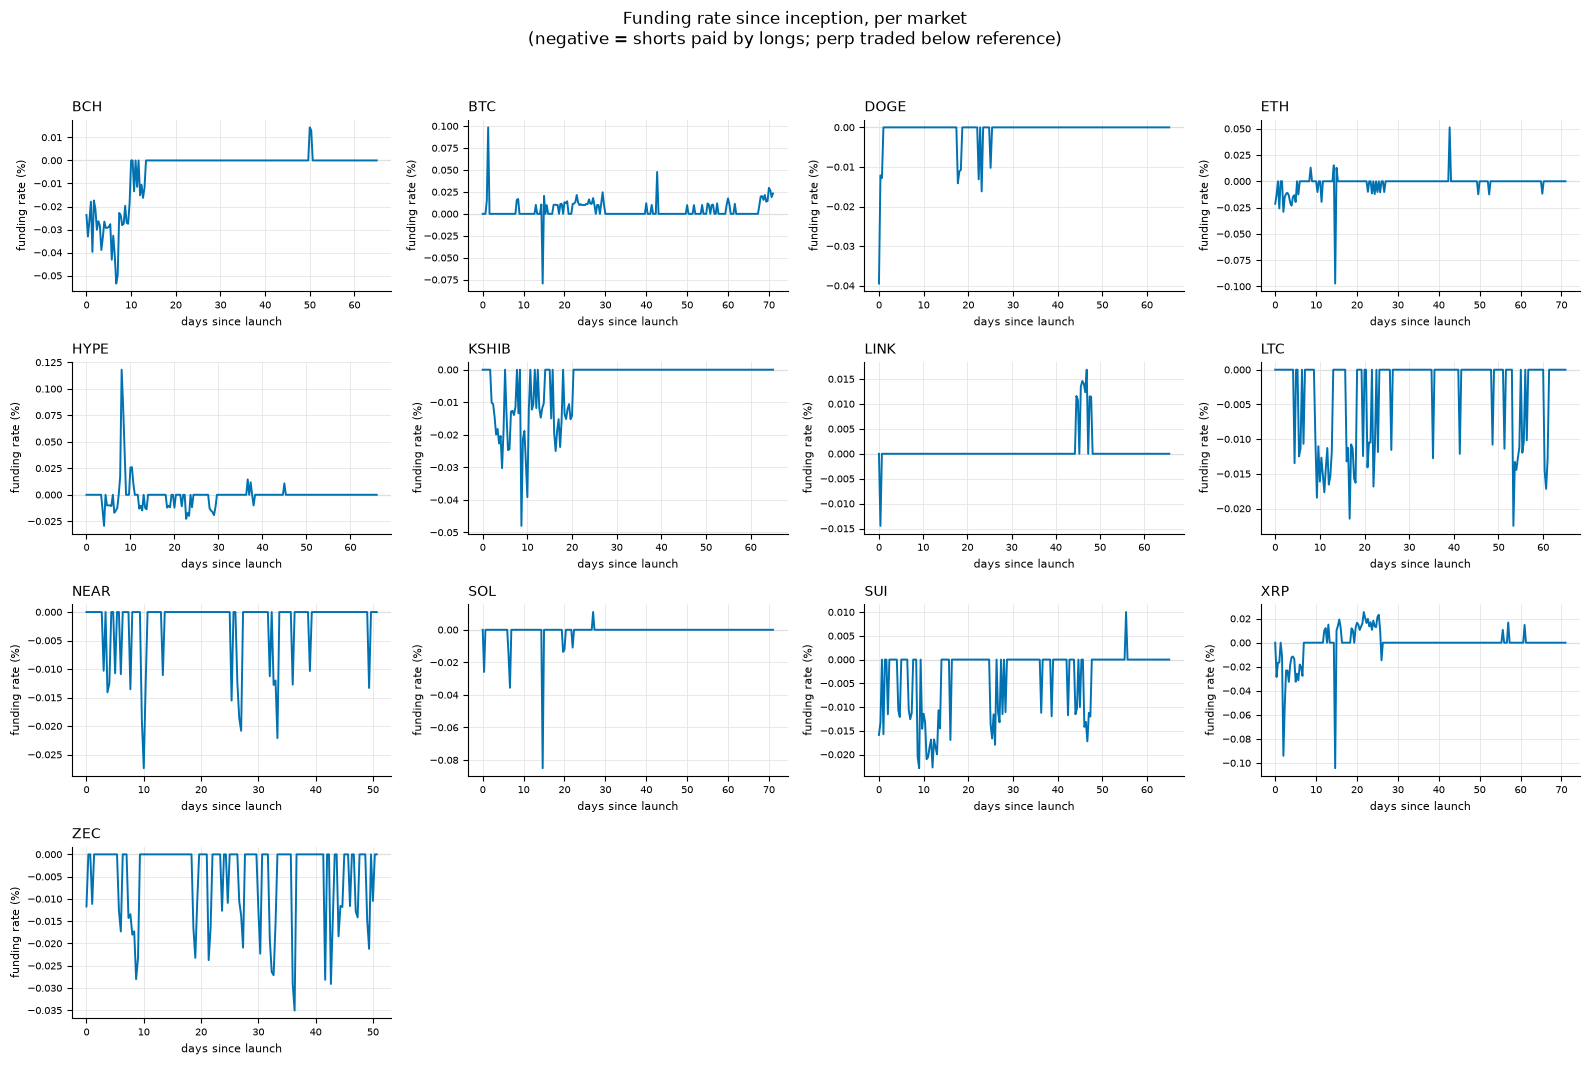

In [3]:
ncols = 4
nrows = -(-len(active_tickers) // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 2.6 * nrows))
axes = axes.flatten()

for ax, ticker in zip(axes, active_tickers):
    sub = funding[funding["market_ticker"] == ticker].sort_values("days_since_launch")
    ax.axhline(0, color="#bbbbbb", linewidth=0.8, zorder=0)
    ax.plot(sub["days_since_launch"], sub["funding_rate"] * 100, color=C_KALSHI, linewidth=1.4)
    ax.set_title(short_name(ticker), fontsize=10, loc="left")
    ax.set_xlabel("days since launch", fontsize=8)
    ax.set_ylabel("funding rate (%)", fontsize=8)
    ax.tick_params(labelsize=7)

for ax in axes[len(active_tickers):]:
    ax.axis("off")

fig.suptitle(
    "Funding rate since inception, per market\n"
    "(negative = shorts paid by longs; perp traded below reference)",
    y=1.02,
)
fig.tight_layout()
plt.show()

## Statistical backing

Pooled regression of |funding_rate| on days-since-launch across all 13
markets, HC1 robust standard errors. No wave-1-vs-alts split, no interaction terms. That
cross-sectional question is real but underpowered at n=13 markets / ~2 months
of data; it lives in exploratory_extensions.ipynb as an honest null, not
here. What's asserted here is only the pooled time trend.

In [4]:
import statsmodels.formula.api as smf

reg_df = funding[funding["market_ticker"].isin(active_tickers)].copy()
reg_df["abs_funding_bps"] = reg_df["funding_rate"].abs() * 1e4

model = smf.ols("abs_funding_bps ~ days_since_launch", data=reg_df).fit(cov_type="HC1")
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:        abs_funding_bps   R-squared:                       0.067
Model:                            OLS   Adj. R-squared:                  0.067
Method:                 Least Squares   F-statistic:                     128.4
Date:                Sun, 30 Aug 2026   Prob (F-statistic):           4.59e-29
Time:                        20:49:15   Log-Likelihood:                -3167.1
No. Observations:                2539   AIC:                             6338.
Df Residuals:                    2537   BIC:                             6350.
Df Model:                           1                                         
Covariance Type:                  HC1                                         
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             0.6988      0.04

## Takeaway

Funding magnitude declines significantly with market age, pooled across all 13
launches, consistent with the AHJ / He-Manela-Ross-von Wachter view of funding
as the mechanism restoring price convergence, observed here at the moment of inception. 